# Tutorial: Inspecting Spectra


<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) European Space Agency, 2026.

This file is subject to the terms and conditions defined in file LICENSE.txt, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file LICENSE.txt.

</div>

**Last modified:** 2026-11-11

**Last update:** DR1-Foundation major update.

**Notebook summary**

This notebook demonstrates how to access, explore, and analyse spectroscopic data stored at data volumes mounted on ESA Datalabs. 
In this tutorial, you will learn how to:

1. Find sources with prominent Halpha lines in the WIDE survey
2. Perform interactive spectral analysis using Jdaviz
3. Retrieve the spectra associated to a list of input WIDE_SURVEY object_id's
4. DEEP Fields: Retrieve red and blue spectra for various sources.
5. DEEP fields: Find objects with multiple spectroscopic observations- A related use case is tackled in the updated Cutouts notebook.


**Useful links:**

* [Euclid DR1 data product description](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [DR1 data release homepage](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [Euclid Astroquery documentation](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)

**Key TAP tables:**

The "spectra_source" ([TAP](https://www.ivoa.net/Documents/TAP/20190927/)) table - and its associated variants, e.g "_deep", "_wide" - contains the metadata required to locate the spectra stored in the Multi-Extension FITS (MEF) files. The relevant fields that define how to access the spectra associated to a given source are the "datalabs_path", "file_name", and "hdu_index".

**Related ADQL queries:**


```sql
SELECT TOP 5 * FROM dr1.spectra_source_deep 
```
```sql
SELECT TOP 5 * FROM dr1.spectra_source_wide
```



**Running the notebook:** 

* This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example. 
* The notebook is intended to be run using the **EUCLID-TOOLS kernel** that has all the necessary packages included. 
* The notebook uses functions from the **n_utils.py Python** file. When moving the notebook you need to move this file as well. You are welcome to modify the utility file for any custom/advanced behaviour you may need.


### Setup

In [1]:
# importing necessary packages
import os
import numpy as np

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table
import specutils
from astroquery.esa.euclid import Euclid

import time
import pandas as pd
import n_utils as utils

%matplotlib inline
import matplotlib.pyplot as plt
from astropy.visualization import astropy_mpl_style
plt.style.use(astropy_mpl_style)

import warnings
from astropy.units import UnitsWarning
warnings.simplefilter("ignore", UnitsWarning)

First let's make a folder (if not already created) to save the output files from this notebook. All the example notebooks save their outputs to this same folder in your user workspace called: `'example_notebook_outputs/'`

In [2]:
#make a folder in your workspace for the output files
output_folder = '/media/user/example_notebook_outputs/'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

**Please note:** When comparing the Q1 and DR1-foundation data releases:
* some table and column names will be different
* specific example source coordinates

It is possible to login using many different options - see the # [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) method for details. Similarly to the archive website for safety reasons this login expires after a period of time. Once this happens the queries to the archive will fail (seemingly without reason). If you are running a personal notebook that requires you to stay logged in for longer - make sure to execute this code line again every once in a while. 

In [3]:
# Alternative ways to login; uncomment your preferred one: ===========
Euclid.login()
# Euclid.login_gui()                                          # Login via graphic interface (pop-up window)
# Euclid.login(user='<user name>', password='<password>')     # 
# Euclid.logout()

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  hcanovas
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid sia service: eas.esac.esa.int:443/sas-sia/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


In [4]:
schema = 'dr1'   # DR1 schema. Change to "q1" to retrieve Q1 data, but please note that the target table names should be adapted accordingly. 

## 1: Find sources with prominent Halpha lines in the WIDE survey

The ADQL query below combines the spectro line features catalog ("spectro_line_features_catalog_spe_line_features_cat") with the "spectra_source" table to identify sources exhibiting strong Halpha line features and retrieve their associated spectra.
* "spectra_source" table: Provides the information required to locate the spectra in the archive, including the "datalabs_path", "file_name", and "hdu_index".
* "spectro_line_features_catalog_spe_line_features_cat" table: contains information about the detected spectral lines, like their (fit) location, signal to noise, or name. As explained in the 
["Euclid Quick Data Release (Q1): Characteristics and limitations of the spectroscopic measurements", Euclid Collaboration: Le Brun et al. (2025)](https://ui.adsabs.harvard.edu/abs/2025arXiv250315308E/abstract), 
each line in this table is fit to different redshift solutions by the SPE Processing Function. The best fit corresponds to spe_rank = 0.




**ADQL query optimisation tip:** The query in the cell below uses the [WITH](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#tth_sEc4.5.1) operator to significantly improve performance. This ensures that:
* the database first select a limited subset ("TOP 10") from the line features table, and
* The JOIN operation is performed afterwards
This way, the query finishes in <1.5 seconds. For comparison, without this optimisation the query usually takes ~ 230 seconds (~4 minutes) to finish.

In [5]:
SN    = 15  # Signal to noise

query = f"""WITH line_cat AS (
    SELECT TOP 3 spe_rank, spe_line_name, spe_line_snr_gf, spe_line_snr_di, spe_line_central_wl_gf, object_id
    FROM {schema}.spectro_line_features_spe_line_features_wide
    WHERE spe_line_name = 'Halpha' AND spe_line_snr_gf > {SN} AND spe_line_snr_di > {SN} AND spe_rank < 2)

SELECT line_cat.*, CONCAT(spe.datalabs_path,'/',spe.file_name) AS full_path, spe.hdu_index, spe.source_id, spe.ra_obj, spe.dec_obj FROM line_cat
JOIN {schema}.spectra_source_wide AS spe
   ON spe.source_id = line_cat.object_id"""

res = utils.get_query_results(Euclid, query=query)

ADQL query: 
WITH line_cat AS (
    SELECT TOP 3 spe_rank, spe_line_name, spe_line_snr_gf, spe_line_snr_di, spe_line_central_wl_gf, object_id
    FROM dr1.spectro_line_features_spe_line_features_wide
    WHERE spe_line_name = 'Halpha' AND spe_line_snr_gf > 15 AND spe_line_snr_di > 15 AND spe_rank < 2)

SELECT line_cat.*, CONCAT(spe.datalabs_path,'/',spe.file_name) AS full_path, spe.hdu_index, spe.source_id, spe.ra_obj, spe.dec_obj FROM line_cat
JOIN dr1.spectra_source_wide AS spe
   ON spe.source_id = line_cat.object_id

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 23.7 seconds


spe_line_name,spe_line_central_wl_gf,spe_line_snr_di,spe_rank,spe_line_snr_gf,object_id,full_path,hdu_index,source_id,ra_obj,dec_obj
NA,Angstrom,NA,NA,NA,,,,,,
object,float64,float64,int16,float64,int64,object,int64,int64,float64,float64
Halpha,18685.021484375,16.030000686645508,1,22.489665985107422,2119561550682976489,/data/euclid_idr1/DR1/R2/SIR_COMBINED_SPECTRA/102160565/EUC_SIR_W-COMBSPEC_102160565_20250823T072312.031692Z.fits,972,2119561550682976489,211.956155067617,68.297648950357
Halpha,14935.4375,57.849998474121094,0,25.98236083984375,2118200465683543061,/data/euclid_idr1/DR1/R2/SIR_COMBINED_SPECTRA/102160565/EUC_SIR_W-COMBSPEC_102160565_20250823T073040.258007Z.fits,691,2118200465683543061,211.820046574048,68.3543061238964
Halpha,16508.18359375,44.689998626708984,0,37.648521423339844,2122657687685191374,/data/euclid_idr1/DR1/R2/SIR_COMBINED_SPECTRA/102160565/EUC_SIR_W-COMBSPEC_102160565_20250823T075251.399462Z.fits,1897,2122657687685191374,212.265768745967,68.5191374160803


### 1.1 Plot spectra
...And highlight the Halpha line detected with a red line.

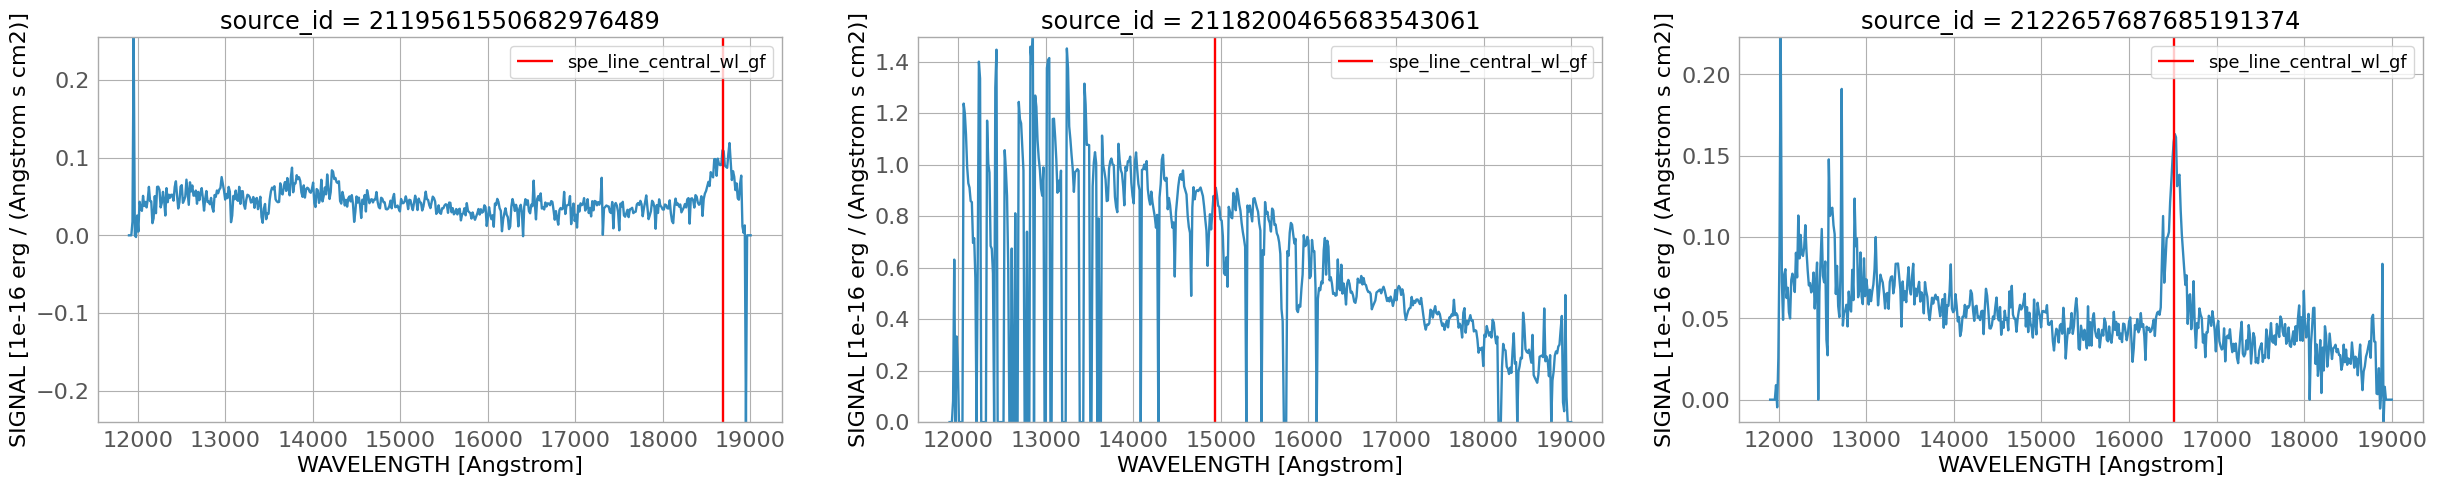

In [6]:
fig = plt.figure(figsize=[30,5])

ii = -1
for row in res:
    ii = ii + 1
    ax = plt.subplot(1,len(res), 1 + ii)
    spec = Table.read(row['full_path'], row['hdu_index'])

    ax.plot(spec['WAVELENGTH'], spec['SIGNAL'])
    ax.vlines(x=row['spe_line_central_wl_gf'], ymin = spec['SIGNAL'].min(), ymax = spec['SIGNAL'].max(), color = 'red', label = 'spe_line_central_wl_gf')
    ax.set_ylim([spec['SIGNAL'].min(), spec['SIGNAL'].max()])
    ax.title.set_text(f"source_id = {row['source_id']}")
    utils.make_canvas(xlabel=f"WAVELENGTH [{spec['WAVELENGTH'].unit}]", ylabel=f"SIGNAL [{spec['SIGNAL'].unit}]", fontsize = 16, legend = True)

plt.show()

## 2. Jdaviz package - Specviz interactive visualization

Here is an example of how to visualize the same spectrum interactively using [Jdaviz](https://jdaviz.readthedocs.io/en/latest/index.html) [Specviz](https://jdaviz.readthedocs.io/en/latest/specviz/index.html). [Specviz](https://jdaviz.readthedocs.io/en/latest/specviz/index.html) is a tool for visualization and quick-look analysis of 1D astronomical spectra (there is also Specviz2D for 2D spectra). It supports:

* flexible spectral unit conversions, custom plotting attributes, interactive selections, multiple plots, and other features
* includes a measurement tool for spectral lines which enables the user, with a few mouse actions, to perform and record measurements. 
* model fitting capability that enables the user to create simple (e.g., single Gaussian) or multi-component models (e.g., multiple Gaussians for emission and absorption lines in addition to regions of flat continua). 
* everything that can be done in the visual interface window can also be done using Python commands. 
* the contents of the viewer or a plot within the plugin can be exported to various image formats. Additionally, spatial and spectral regions can be exported to files.

You can find extensive guides, documentation and examples on how to use Specviz here: 

**Disclaimer**

1. [Jdaviz](https://jdaviz.readthedocs.io/en/latest/index.html) package is in active development so some bugs may occur. 
2. Keep in mind that the aim of this notebook is to demonstrate the functinalities that are available and how to use them, not to necessarily provide a 100% valid scientific use case.
3. For more examples showing how to use this package, please see the associated documentation and also the version "_v2" of this notebook

### 2.1 Creating empty Specviz window

In the following cel we create a Specviz instance and show the (for now) empty window. The viewer can be displayed either in the output of the cell below or alternatively on the side of the notebook (especially helpful when you have a wider screen). Note that everything we do in the code cells beyond this point will update this same display and can also be done by using the buttons in the user interface. Since we are updating the same display please run the cells below one at a time (not "run all"). This way you can look at the viewer after each cell to see the changes and we also make sure that the previous command is completed before sending a new one to Specviz.

In [7]:
from jdaviz import Specviz
from specutils import Spectrum1D

# Suppress warnings
# with warnings.catch_warnings():
#     warnings.simplefilter("ignore")

specviz = Specviz()
viewer = specviz.app.get_viewer('spectrum-viewer')

# showing the viewer embedded into this notebook
specviz.show()

# showing the viewer on the side of the notebook
# specviz.show('sidecar', height=1000)

<IPython.core.display.Javascript object>

/tmp/ipykernel_5410/164278009.py:8: DeprecationWarning: Specviz is deprecated and will be removed in version 5.2. Please use the top-level App instead.
  specviz = Specviz()
        Use ._app instead. [warnings]


PrivateApplication(config='specviz', docs_link='https://jdaviz.readthedocs.io/en/v5.0.5/specviz/index.html', e…

### 2.2 Loading spectra data

The last spectra plotted in Example #1 above is loaded into the Specviz viewer. This can be done in the interface by using the blue "import data" button at the top left of the viewer. The loading process takes tipically a few seconds. Below are two examples for loading the file, one from the big combined spectra file and one from the smaller file we scraped together before which is a lot faster. 

Jdaviz doesn't like how the units are defined in the spectra file and will give a lot of warnings about it even though the spectra is loaded correctly. This is why we ignore warnings when loading the data in the cell below.

In [8]:
# Loading the last spectra displayed before
source_filepath = row['full_path']
source_ext      = row['hdu_index']

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    spec1d = Spectrum1D.read(source_filepath, hdu=source_ext, store_data_header=False) 
    specviz.load_data(spec1d)

## 3: Retrieve the spectra associated to a list of input WIDE_SURVEY object_id's

As explained in the complementary "Astroquery" notebook (see its Sect. 8.2.1 for details), the Archive table upload capability is highly flexible and supports multiple upload options. For additional guidancem please refer to the Gaia Archive [Upload a user table](https://www.cosmos.esa.int/web/gaia-users/archive/collaborate#UploadUserTable), as both the Astroquery.Euclid and Astroquery.Gaia packages share the user management functionalities. 

For simplicity, in this example we create an Astropy table from scratch.

**Notes:**
* The WIDE Survey only includes "RED" grism spectra (the DEEP survey includes both BLUE & RED).

### 3.1: Create input target list

In [9]:
my_sources = [-442110049422479480, -442100541422519991, -442110317422523962]
my_table   = Table({'dr1_deep_sources':my_sources})
table_name = 'spec_tutorial_input'       # Table name at the user space
my_table

dr1_deep_sources
int64
-442110049422479480
-442100541422519991
-442110317422523962


### 3.2: Upload table to the user space

The code below first checks if the user table is already present in the Archive user space.

**Note:** Please remember to **not** include special [ADQL characters](https://www.ivoa.net/documents/ADQL/20230418/PR-ADQL-2.1-20230418.pdf) in the table name (e.g., a dot "." or a minus sign "-" can generate problems when trying to access to the user table in the database). We also recommmend to not use capital letters in the table name.

In [10]:
user       = Euclid._TapPlus__user                                                                                # User name
utables    = Euclid.load_tables(only_names=True)                                                                  # Get names of Archive tables
my_utables = [utable.get_qualified_name() for utable in utables if f'user_{user}' in utable.get_qualified_name()] # Extract user table names
print(f'User tables found in the Archive: ')
for my_utable in my_utables:
    print(f'* {my_utable}')
    

fq_name    = f'user_{user}.{table_name}'
if fq_name in my_utables:
    print(f'* Warning: {table_name} exist on the user space - stopping table upload')
else:
    Euclid.upload_table(upload_resource=my_table, table_name = table_name)

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
User tables found in the Archive: 
* user_hcanovas.des_target_sources
* user_hcanovas.input_spec_list
* user_hcanovas.my_q1_source_list
* user_hcanovas.spec_tutorial_input
* Warning: spec_tutorial_input exist on the user space - stopping table upload


### 3.3: (LEFT) JOIN with the spectra_source table

The query below applies a ```LEFT JOIN``` operation so that all the sources in the user table are included in the query output (even if there is no specra associated to them),

**Notes:** 
* One of the sources in the input source list has no associated spectra; it appears with NULL values in the retrieved table.
* Order matters: the LEFT JOIN operation is very sensitive to the order and sizes of the tables involved. In the example below, the "left" table is the smaller one (the user table).
* If speed matters, try a "JOIN" instead of the "LEFT JOIN". The default (inner) "JOIN" is faster, but only the rows that are common to the two JOINed tables are returned.

In [11]:
query = f"""select my_table.*, spe.source_id,  spe.ra_obj, spe.dec_obj, spe.datalabs_path, spe.file_name, spe.hdu_index
FROM user_{user}.{table_name} AS my_table
LEFT JOIN {schema}.spectra_source_wide AS spe
  ON my_table.dr1_deep_sources = spe.source_id"""

res = utils.get_query_results(Euclid, query)

ADQL query: 
select my_table.*, spe.source_id,  spe.ra_obj, spe.dec_obj, spe.datalabs_path, spe.file_name, spe.hdu_index
FROM user_hcanovas.spec_tutorial_input AS my_table
LEFT JOIN dr1.spectra_source_wide AS spe
  ON my_table.dr1_deep_sources = spe.source_id

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 27.8 seconds


spec_tutorial_input_oid,dr1_deep_sources,source_id,ra_obj,dec_obj,datalabs_path,file_name,hdu_index
int32,int64,int64,float64,float64,object,object,int64
3,-442110317422523962,-442110317422523962,44.2110317776168,-42.2523962434437,/data/euclid_idr1/DR1/R2/SIR_COMBINED_SPECTRA/102027084,EUC_SIR_W-COMBSPEC_102027084_20250825T085535.567407Z.fits,2400
2,-442100541422519991,-442100541422519991,44.2100541147383,-42.2519991834116,/data/euclid_idr1/DR1/R2/SIR_COMBINED_SPECTRA/102027084,EUC_SIR_W-COMBSPEC_102027084_20250825T085535.567407Z.fits,2419
1,-442110049422479480,--,--,--,,,--


### 3.4: Read the spectra

Below we identify the sources with associated spectra, and then we plot them.

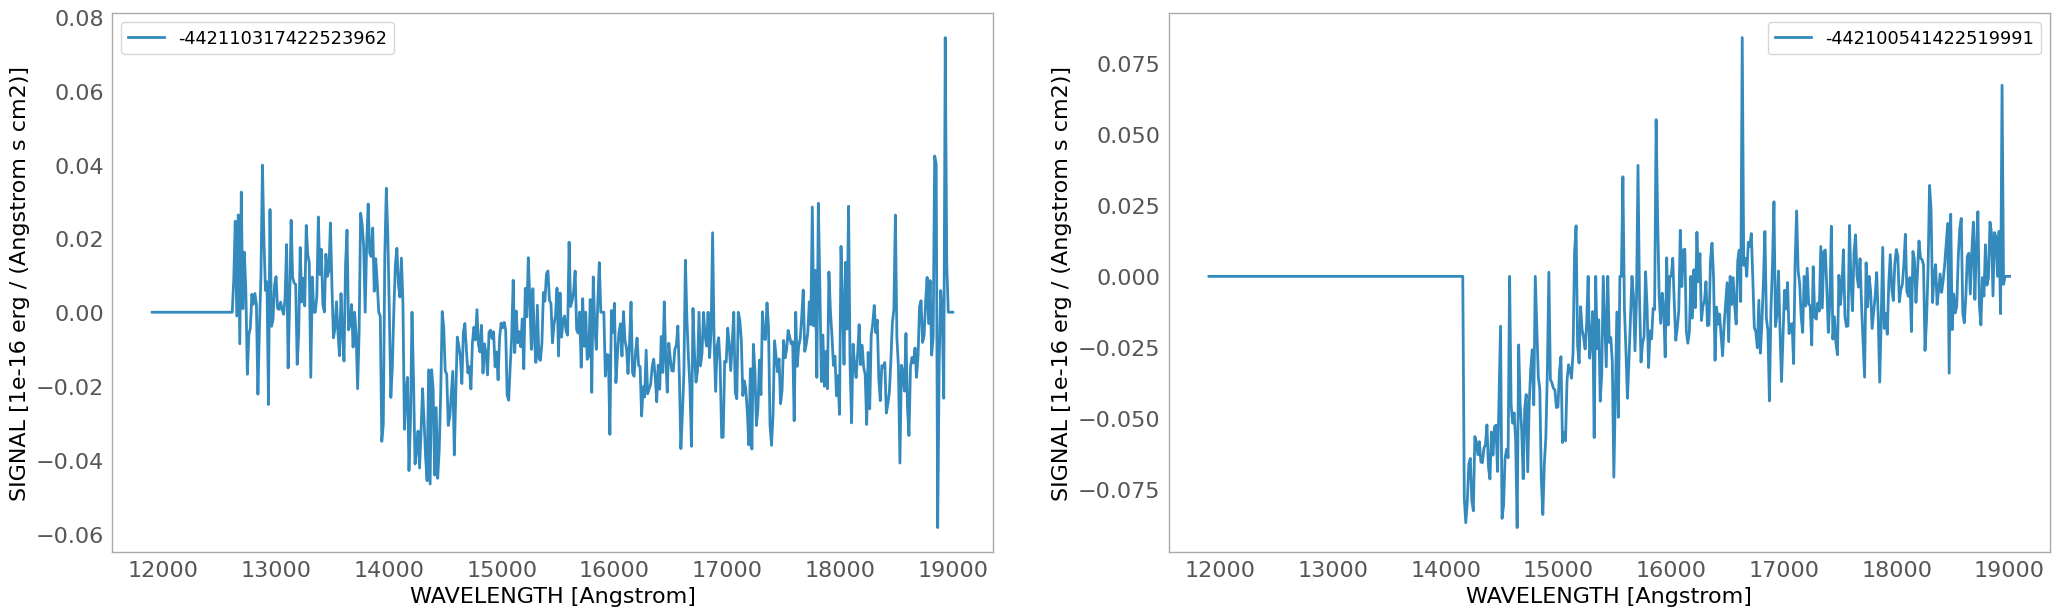

In [12]:
# Gather the data ===========================
masks = res['source_id'].mask # The source without spectra is "masked" in the Astropy table.

spec_list = []
for ii in range(len(res)):
    if masks[ii] == False:
        spec = Table.read(res['datalabs_path'][ii] + '/' + res['file_name'][ii], res['hdu_index'][ii])
        spec.source_id = res['source_id'][ii]
        spec_list.append(spec)
        
# Plot ======================================
fontsize = 14
fig = plt.figure(figsize=[25,7])
ii = -1
for spec in spec_list:  
    ii = ii + 1
    plt.subplot(1,2,1 + ii)
    plt.plot(spec['WAVELENGTH'],  spec['SIGNAL'], label = f'{spec.source_id}', linewidth = 2)
    plt.grid()
    utils.make_canvas(xlabel=f"WAVELENGTH [{spec['WAVELENGTH'].unit}]", ylabel=f"SIGNAL [{spec['SIGNAL'].unit}]", fontsize = 16, legend = True)
plt.show()

## 4: DEEP Survey: Retrieve red & blue spectra


**Notes:**
* For reference: in Q1 only the RED grism is available.
* EDFF central coordinates: 03:31:43.6 -28:05:18.6
* Relevant TAP tables:
    * dr1.mer_catalogue_deep_survey  (to obtain selected fields)
    * dr1.spectra_source_deep        (to obtain the file_path & hdu information)
    * dr1.combined_spectra           (to obtain the wavelength coverage)
    
Look at the result table: there are two rows per object_id: one for the red and other for the blue spectra

In [13]:
coords_edff = SkyCoord('03:31:43.6 -28:05:18.6', unit=(u.hourangle, u.deg))

rad   = 0.5/60.                       # Cone search radius: Half arcminute
query = f"""SELECT TOP 6 mer.right_ascension, mer.declination, mer.designation, mer.object_id, mer.patch_id_list, mer.det_quality_flag, mer.flux_vis_sersic, mer.segmentation_map_id, mer.segmentation_area, spe.datalabs_path, spe.file_name, spe.dith_num, spe.hdu_index,
combined.lambda_range, DISTANCE({coords_edff.ra.deg}, {coords_edff.dec.deg}, mer.right_ascension, mer.declination)*3600. AS dist_arcsec
FROM {schema}.mer_catalogue_deep_survey AS mer
JOIN {schema}.spectra_source_deep AS spe
  ON spe.source_id = mer.object_id
JOIN {schema}.combined_spectra AS combined
 ON spe.combined_spectra_fk = combined.combined_spectra_oid  
WHERE DISTANCE({coords_edff.ra.deg}, {coords_edff.dec.deg}, mer.right_ascension, mer.declination) < {rad}
ORDER BY dist_arcsec ASC, lambda_range"""


res = utils.get_query_results(Euclid, query)

ADQL query: 
SELECT TOP 6 mer.right_ascension, mer.declination, mer.designation, mer.object_id, mer.patch_id_list, mer.det_quality_flag, mer.flux_vis_sersic, mer.segmentation_map_id, mer.segmentation_area, spe.datalabs_path, spe.file_name, spe.dith_num, spe.hdu_index,
combined.lambda_range, DISTANCE(52.93166666666666, -28.0885, mer.right_ascension, mer.declination)*3600. AS dist_arcsec
FROM dr1.mer_catalogue_deep_survey AS mer
JOIN dr1.spectra_source_deep AS spe
  ON spe.source_id = mer.object_id
JOIN dr1.combined_spectra AS combined
 ON spe.combined_spectra_fk = combined.combined_spectra_oid  
WHERE DISTANCE(52.93166666666666, -28.0885, mer.right_ascension, mer.declination) < 0.008333333333333333
ORDER BY dist_arcsec ASC, lambda_range

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 17.7 seconds


right_ascension,declination,designation,object_id,patch_id_list,det_quality_flag,flux_vis_sersic,segmentation_map_id,segmentation_area,datalabs_path,file_name,dith_num,hdu_index,lambda_range,dist_arcsec
deg,deg,,NA,,NA,uJy,NA,pix,,,,,,
float64,float64,object,int64,int64[8],int16,float64,int64,int32,object,object,int64,int64,object,float64
52.93184352285523,-28.087050070886352,Euclid DR1 J033143.642-280513.38,-529318435280870500,58 .. 0,0,12.067377090454102,101375805005694,596,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101375805,EUC_SIR_W-COMBSPEC_101375805_20250821T112508.724665Z.fits,2,333,BGS,5.249880102915558
52.93184352285523,-28.087050070886352,Euclid DR1 J033143.642-280513.38,-529318435280870500,58 .. 0,0,12.067377090454102,101375805005694,596,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101375805,EUC_SIR_W-COMBSPEC_101375805_20250821T101727.456140Z.fits,3,335,RGS,5.249880102915558
52.92943776011155,-28.087081959503795,Euclid DR1 J033143.065-280513.49,-529294377280870819,58 .. 0,0,0.6056307554244995,101375805005693,98,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101375805,EUC_SIR_W-COMBSPEC_101375805_20250821T112508.724665Z.fits,2,373,BGS,8.7277363408611
52.92943776011155,-28.087081959503795,Euclid DR1 J033143.065-280513.49,-529294377280870819,58 .. 0,0,0.6056307554244995,101375805005693,98,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101375805,EUC_SIR_W-COMBSPEC_101375805_20250821T101727.456140Z.fits,3,385,RGS,8.7277363408611
52.93071526759942,-28.090864599157733,Euclid DR1 J033143.371-280527.11,-529307152280908645,58 .. 0,2,0.9071683287620544,101375805005167,117,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101375805,EUC_SIR_W-COMBSPEC_101375805_20250821T112508.724665Z.fits,2,355,BGS,9.032925151304493
52.93071526759942,-28.090864599157733,Euclid DR1 J033143.371-280527.11,-529307152280908645,58 .. 0,2,0.9071683287620544,101375805005167,117,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101375805,EUC_SIR_W-COMBSPEC_101375805_20250821T101727.456140Z.fits,3,363,RGS,9.032925151304493


### 4.1 Read the MEF files 

... That contain the spectra

In [14]:
object_ids = list(set(res['object_id'])) # Removing duplication in the object_id.

dict_list = []
for object_id in object_ids:
    subset = res[res['object_id'] == object_id]    
    spec_b = Table.read(subset['datalabs_path'][0] + '/' + subset['file_name'][0], subset['hdu_index'][0])
    spec_r = Table.read(subset['datalabs_path'][1] + '/' + subset['file_name'][1], subset['hdu_index'][1])
    spec_b.object_id = object_id
    dict_list.append({'object_id':object_id, 'RGS':spec_r, 'BGS':spec_b})

### 4.2 Plot the spectra

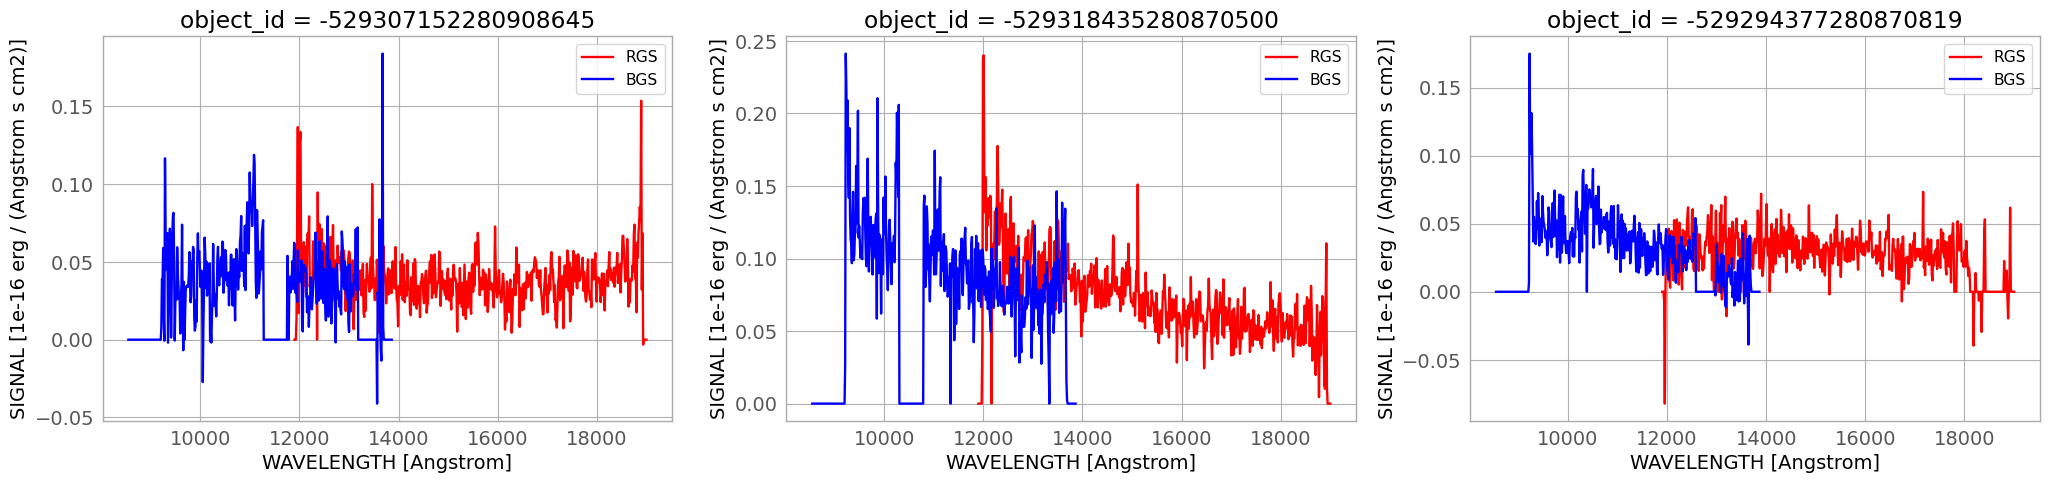

In [15]:
fig = plt.figure(figsize=[25,5])
fontsize = 14
ii = -1
for inp in dict_list:

    ii = ii + 1
    plt.subplot(1,3,1 + ii)
    
    plt.title(f"object_id = {inp['object_id']}", fontsize = fontsize * 1.2)
    colors = iter(['red', 'blue'])
    for flag in ['RGS', 'BGS']:
        plt.plot(inp[flag]['WAVELENGTH'],  inp[flag]['SIGNAL'], label = flag, color = next(colors))
        plt.grid()
    utils.make_canvas(xlabel=f"WAVELENGTH [{inp[flag]['WAVELENGTH'].unit}]", ylabel=f"SIGNAL [{inp[flag]['SIGNAL'].unit}]", fontsize = 14, legend = True)
plt.show()

## 5: Find objects with multiple spectroscopic observations (DEEP fields)


* Relevant TAP table: catalogue.mer_catalogue_deep_survey (to find sources observed multiple times)    <span style="color:red">**The table name needs to be changed when the new tap schema is applied.** </span>
* Relevant table field: patch_id_list - see how the UDF ESDC_ARRAY_LENGTH is used to find sources observed during multiple visits.
* In the North field there were 8 visits with RED spectra, whereas in the BLUE there were 3 visits.

### 5.1 Find suitable sources

key field: "the patch_id_list"

In [16]:
query = f"""SELECT TOP 3 designation, object_id, right_ascension, declination, tile_index, patch_id_list, ESDC_ARRAY_LENGTH(patch_id_list,1)
FROM {schema}.mer_catalogue_deep_survey
WHERE ESDC_ARRAY_LENGTH(patch_id_list,1) = 10"""

res = utils.get_query_results(Euclid, query)

ADQL query: 
SELECT TOP 3 designation, object_id, right_ascension, declination, tile_index, patch_id_list, ESDC_ARRAY_LENGTH(patch_id_list,1)
FROM dr1.mer_catalogue_deep_survey
WHERE ESDC_ARRAY_LENGTH(patch_id_list,1) = 10

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 16.8 seconds


designation,object_id,right_ascension,declination,tile_index,patch_id_list,ARRAY_LENGTH
,NA,deg,deg,,,
object,int64,float64,float64,int64,int64[8],int32
Euclid DR1 J182646.946+662253.44,2766956112663815113,276.69561125140814,66.38151136749268,101835225,38 .. 114,10
Euclid DR1 J182651.693+662256.84,2767153890663824569,276.7153890556064,66.38245693744484,101835225,38 .. 114,10
Euclid DR1 J182816.690+662257.14,2770695445663825393,277.06954450622743,66.38253934487695,101835225,38 .. 114,10


For this example, we will use one source that is known to have multiple visits, with spectra and image data.

In [17]:
object_id = 2688124142666475971 # AGN at z=1 in EDFN. 
#Other interesting source: 2661957271668287048 (edge-on AGN from T. Matamoro Zatarain et al.: The active galaxies of Euclid)

query = f"""SELECT designation, object_id, right_ascension, declination, tile_index, patch_id_list, ESDC_ARRAY_LENGTH(patch_id_list,1)
FROM {schema}.mer_catalogue_deep_survey
WHERE object_id = {object_id}"""

res = utils.get_query_results(Euclid, query)

ADQL query: 
SELECT designation, object_id, right_ascension, declination, tile_index, patch_id_list, ESDC_ARRAY_LENGTH(patch_id_list,1)
FROM dr1.mer_catalogue_deep_survey
WHERE object_id = 2688124142666475971

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 16.7 seconds


designation,object_id,right_ascension,declination,tile_index,patch_id_list,ARRAY_LENGTH
,NA,deg,deg,,,
object,int64,float64,float64,int64,int64[8],int32
Euclid DR1 J175514.979+663851.35,2688124142666475971,268.8124142787188,66.6475971869471,101835788,38 .. 114,11


### 5.2 (small) Cone search around the source coordinates

The target source will have slightly different coordinates in the different realisations of the "deep visits" catalogue. To identify target source, a cone search with a 1" radius centred on the "deep survey" coordinates is launched.

**Notes:** 
It can happen that some visits listed in the DEEP SURVEY catalogue are not listed in the DEEP_VISITS below.

In [18]:
coords_ra  = res['right_ascension'][0]
coords_dec = res['declination'][0]
rad        = 1/3600. # 1 arcseconds

query = f"""SELECT right_ascension, declination, designation, object_id, tile_index, patch_id_list, vis_det, det_quality_flag, flux_detection_total, flux_vis_sersic,
segmentation_map_id, segmentation_area, DISTANCE({coords_ra}, {coords_dec}, right_ascension, declination)*3600. AS dist_arcsec
FROM {schema}.mer_catalogue_deep_visits
WHERE DISTANCE({coords_ra}, {coords_dec}, right_ascension, declination) < {rad}
ORDER BY patch_id_list"""

res = utils.get_query_results(Euclid, query)

ADQL query: 
SELECT right_ascension, declination, designation, object_id, tile_index, patch_id_list, vis_det, det_quality_flag, flux_detection_total, flux_vis_sersic,
segmentation_map_id, segmentation_area, DISTANCE(268.8124142787188, 66.6475971869471, right_ascension, declination)*3600. AS dist_arcsec
FROM dr1.mer_catalogue_deep_visits
WHERE DISTANCE(268.8124142787188, 66.6475971869471, right_ascension, declination) < 0.0002777777777777778
ORDER BY patch_id_list

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 17.6 seconds


right_ascension,declination,designation,object_id,tile_index,patch_id_list,vis_det,det_quality_flag,flux_detection_total,flux_vis_sersic,segmentation_map_id,segmentation_area,dist_arcsec
deg,deg,,NA,,,NA,NA,uJy,uJy,NA,pix,
float64,float64,object,int64,int64,int64,int16,int16,float64,float64,int64,int32,float64
268.8124190420673,66.6475974278564,Euclid DR1 J175514.980+663851.35,2688124190666475974,102159486,39,1,2,14.389762878417969,14.576122283935547,102159486077072,272,0.0068523428155623746
268.8124183452948,66.64759743443175,Euclid DR1 J175514.980+663851.35,2688124183666475974,102159486,44,1,0,14.610295295715332,14.796005249023438,102159486077156,275,0.005870948485387208
268.8124154337758,66.64759722358156,Euclid DR1 J175514.979+663851.35,2688124154666475972,102159486,49,1,0,15.388643264770508,15.378669738769531,102159486076935,260,0.0016535195514228952
268.8124122139963,66.64759652980936,Euclid DR1 J175514.978+663851.35,2688124122666475965,102159486,57,1,0,15.179048538208008,14.852352142333984,102159486077084,294,0.00377854379842956
268.81241312420985,66.64759795398962,Euclid DR1 J175514.979+663851.35,2688124131666475979,102159486,64,1,0,15.190481185913086,15.294349670410156,102159486077730,274,0.0032154667833326715
268.81240800552666,66.64759574448236,Euclid DR1 J175514.977+663851.34,2688124080666475957,102159486,99,1,0,16.514841079711914,16.523481369018555,102159486075731,280,0.010348914726671505
268.8124151117189,66.64759757966317,Euclid DR1 J175514.979+663851.35,2688124151666475975,102159486,114,1,2,15.506856918334961,15.619490623474121,102159486073544,311,0.0018470867040115441
268.8124096358153,66.64759669986377,Euclid DR1 J175514.978+663851.35,2688124096666475966,102159486,130,1,0,16.09809112548828,16.165904998779297,102159486073065,305,0.006853481801334715


In [19]:
# DEEP VISITS VS. DEEP SURVEY Coordinates (max/min/diff)
print(f"{res['dist_arcsec'].max():5.3f}, {res['dist_arcsec'].min():5.3f}, {res['dist_arcsec'].max() - res['dist_arcsec'].min() :5.3f}")

0.018, 0.002, 0.016


### 5.3 (small) Cone search around the source coordinates + JOIN spectra

Not every measurement has an associated spectra. The query below repeats the query above but it also adds a JOIN operation with the "spectra_source_deep_visits" table.

In [20]:
query = f"""SELECT mer.right_ascension, mer.declination, mer.designation, mer.object_id, mer.tile_index, mer.patch_id_list, mer.vis_det,
mer.det_quality_flag, mer.flux_detection_total, mer.flux_vis_sersic, mer.segmentation_map_id, mer.segmentation_area, 
DISTANCE({coords_ra}, {coords_dec}, mer.right_ascension, mer.declination)*3600. AS dist_arcsec, spe.*, combined.lambda_range
FROM {schema}.mer_catalogue_deep_visits AS mer
JOIN {schema}.spectra_source_deep_visits AS spe
  ON spe.source_id = mer.object_id
JOIN {schema}.combined_spectra AS combined
 ON spe.combined_spectra_fk = combined.combined_spectra_oid
WHERE DISTANCE({coords_ra}, {coords_dec}, mer.right_ascension, mer.declination) < {rad}
ORDER BY dist_arcsec ASC"""

res = utils.get_query_results(Euclid, query, output_format='ecsv')

ADQL query: 
SELECT mer.right_ascension, mer.declination, mer.designation, mer.object_id, mer.tile_index, mer.patch_id_list, mer.vis_det,
mer.det_quality_flag, mer.flux_detection_total, mer.flux_vis_sersic, mer.segmentation_map_id, mer.segmentation_area, 
DISTANCE(268.8124142787188, 66.6475971869471, mer.right_ascension, mer.declination)*3600. AS dist_arcsec, spe.*, combined.lambda_range
FROM dr1.mer_catalogue_deep_visits AS mer
JOIN dr1.spectra_source_deep_visits AS spe
  ON spe.source_id = mer.object_id
JOIN dr1.combined_spectra AS combined
 ON spe.combined_spectra_fk = combined.combined_spectra_oid
WHERE DISTANCE(268.8124142787188, 66.6475971869471, mer.right_ascension, mer.declination) < 0.0002777777777777778
ORDER BY dist_arcsec ASC

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 21.9 seconds


right_ascension,declination,designation,object_id,tile_index,patch_id_list,vis_det,det_quality_flag,flux_detection_total,flux_vis_sersic,segmentation_map_id,segmentation_area,dist_arcsec,calblock_id_list,combined_spectra_fk,combined_spectra_product_fk,datalabs_path,dec_obj,dith_num,file_name,file_path,hdu_index,patch_id_list_1,ra_obj,source_id,spectra_source_oid,to_be_published,lambda_range
deg,deg,,NA,,,NA,NA,uJy,uJy,NA,pix,,,,,,,,,,,,,,,,
float64,float64,str32,int64,int64,int64,int16,int16,float64,float64,int64,int32,float64,object,int64,int64,str55,float64,int64,str57,str65,int64,int64,float64,int64,int64,int32,str3
268.8124154337758,66.64759722358156,Euclid DR1 J175514.979+663851.35,2688124154666475972,102159486,49,1,0,15.388643264770508,15.378669738769531,102159486076935,260,0.0016535195514228952,['CALBLOCK-F-003'],3108,199658,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475972235816,4,EUC_SIR_W-COMBSPEC_102159486_20250823T070707.506553Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,751,49,268.812415433776,2688124154666475972,39463516,1,RGS
268.8124151117189,66.64759757966317,Euclid DR1 J175514.979+663851.35,2688124151666475975,102159486,114,1,2,15.506856918334961,15.619490623474121,102159486073544,311,0.0018470867040115441,['CALBLOCK-F-003'],6110,496942,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475975796632,4,EUC_SIR_W-COMBSPEC_102159486_20250823T182236.882811Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,732,114,268.812415111719,2688124151666475975,114728543,1,RGS
268.81241312420985,66.64759795398962,Euclid DR1 J175514.979+663851.35,2688124131666475979,102159486,64,1,0,15.190481185913086,15.294349670410156,102159486077730,274,0.0032154667833326715,['CALBLOCK-F-003'],2947,184163,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475979539896,4,EUC_SIR_W-COMBSPEC_102159486_20250823T080723.698270Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,757,64,268.81241312421,2688124131666475979,35479445,1,RGS
268.8124122139963,66.64759652980936,Euclid DR1 J175514.978+663851.35,2688124122666475965,102159486,57,1,0,15.179048538208008,14.852352142333984,102159486077084,294,0.00377854379842956,['CALBLOCK-F-003'],6163,502394,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475965298094,3,EUC_SIR_W-COMBSPEC_102159486_20250823T161507.209908Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,667,57,268.812412213996,2688124122666475965,116048073,1,RGS
268.8124111494279,66.64759925196044,Euclid DR1 J175514.978+663851.36,2688124111666475992,102159486,151,1,0,14.490004539489746,14.899300575256348,102159486074077,258,0.008672103914871847,['CALBLOCK-F-003'],6088,494875,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475992519604,4,EUC_SIR_W-COMBSPEC_102159486_20250823T152148.236419Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,785,151,268.812411149428,2688124111666475992,114174169,1,RGS
268.81240800552666,66.64759574448236,Euclid DR1 J175514.977+663851.34,2688124080666475957,102159486,99,1,0,16.514841079711914,16.523481369018555,102159486075731,280,0.010348914726671505,['CALBLOCK-F-003'],6206,506809,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475957444824,3,EUC_SIR_W-COMBSPEC_102159486_20250823T144410.742623Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,804,99,268.812408005527,2688124080666475957,117140596,1,RGS
268.81242530523895,66.64759489298966,Euclid DR1 J175514.982+663851.34,2688124253666475948,102159486,171,0,0,20.98210906982422,5.95076322555542,102159486179692,774,0.017770187543263986,['CALBLOCK-F-003'],9386,788036,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475948929897,4,EUC_SIR_W-COMBSPEC_102159486_20250824T102330.062734Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,354,171,268.812425305239,2688124253666475948,183278783,1,RGS


### 5.4 Plot spectra

The spectra can be read using different tools. In the example below we use the [Astropy.tables](https://docs.astropy.org/en/stable/table/index.html) package.

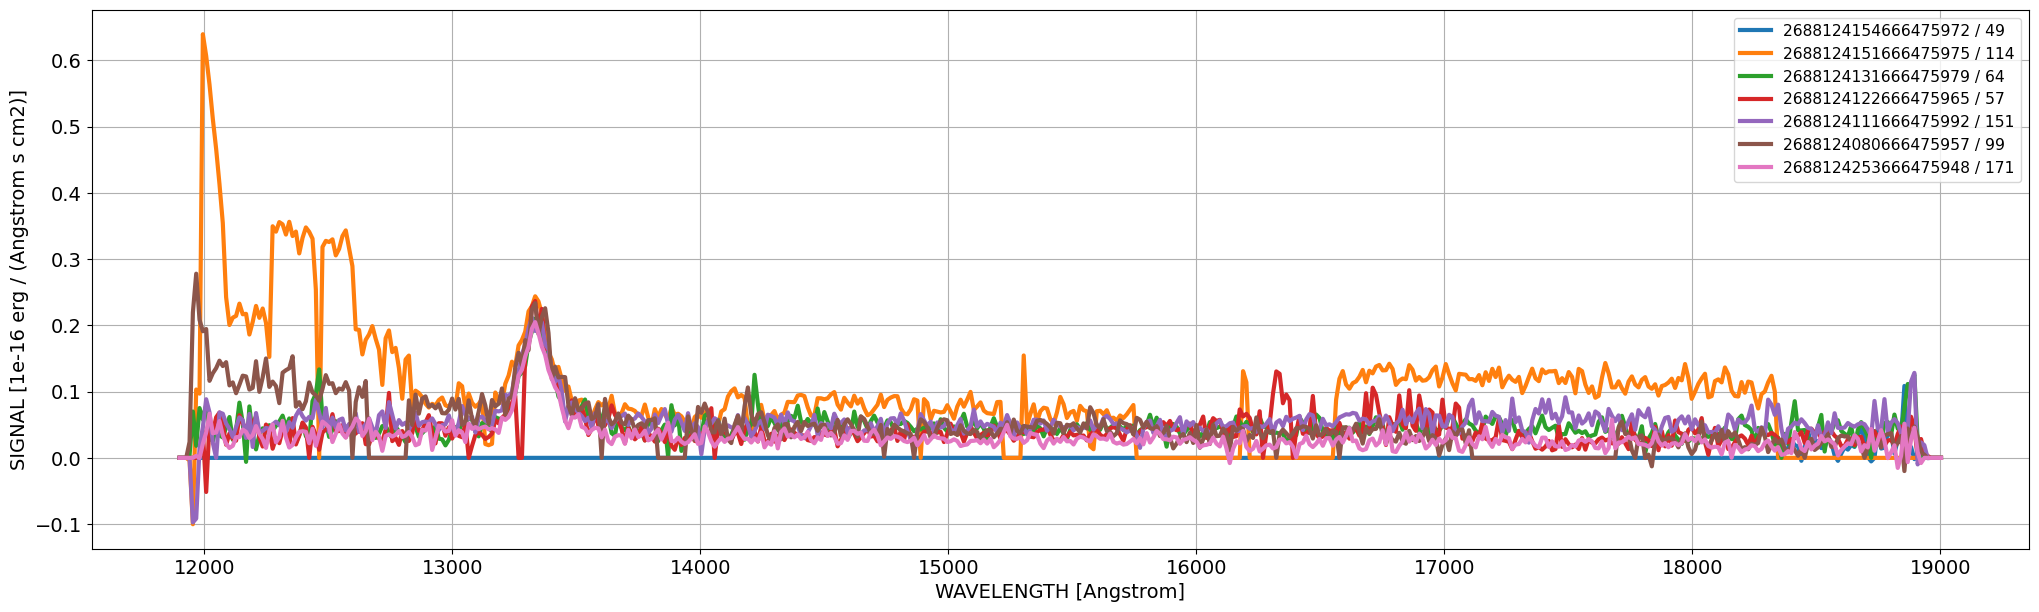

In [21]:
rr       = len(res)
specs    = [Table.read(res['datalabs_path'][ii] + '/' + res['file_name'][ii], res['hdu_index'][ii]) for ii in range(rr)]
objs     = [res['object_id'][ii]                                                                    for ii in range(rr)]
patch_id = [res['patch_id_list'][ii]                                                                for ii in range(rr)]


fig = plt.figure(figsize=[25,7])
plt.rcdefaults()
for ii in range(rr):  
    plt.plot(specs[ii]['WAVELENGTH'],  specs[ii]['SIGNAL'], label = f'{objs[ii]} / {patch_id[ii]}', linewidth = 3)
utils.make_canvas(xlabel=f"WAVELENGTH [{specs[0]['WAVELENGTH'].unit}]", ylabel=f"SIGNAL [{specs[0]['SIGNAL'].unit}]", fontsize = 14, legend = True)
plt.grid()
plt.show()

### Add DEEP spectra for comparison, and identify the prominent broad line using the "spectro_line_features_spe_line_features_deep" table

In [22]:
query = f"""SELECT mer.designation, mer.object_id, mer.right_ascension, mer.declination, mer.tile_index, spe.*, combined.lambda_range
FROM {schema}.mer_catalogue_deep_survey AS mer
JOIN {schema}.spectra_source_deep AS spe
   ON spe.source_id = mer.object_id
JOIN {schema}.combined_spectra AS combined
 ON spe.combined_spectra_fk = combined.combined_spectra_oid
WHERE object_id = {object_id}"""

res = utils.get_query_results(Euclid, query, output_format='ecsv')

ADQL query: 
SELECT mer.designation, mer.object_id, mer.right_ascension, mer.declination, mer.tile_index, spe.*, combined.lambda_range
FROM dr1.mer_catalogue_deep_survey AS mer
JOIN dr1.spectra_source_deep AS spe
   ON spe.source_id = mer.object_id
JOIN dr1.combined_spectra AS combined
 ON spe.combined_spectra_fk = combined.combined_spectra_oid
WHERE object_id = 2688124142666475971

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 25.4 seconds


designation,object_id,right_ascension,declination,tile_index,calblock_id_list,combined_spectra_fk,combined_spectra_product_fk,datalabs_path,dec_obj,dith_num,file_name,file_path,hdu_index,patch_id_list,ra_obj,source_id,spectra_source_oid,to_be_published,lambda_range
,NA,deg,deg,,,,,,,,,,,,,,,,
str32,int64,float64,float64,int64,object,int64,int64,str55,float64,int64,str57,str65,int64,int64[10],float64,int64,int64,int32,str3
Euclid DR1 J175514.979+663851.35,2688124142666475971,268.8124142787188,66.6475971869471,101835788,['CALBLOCK-F-003'],11628,1001243,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101835788,66.6475971869471,30,EUC_SIR_W-COMBSPEC_101835788_20250908T060800.042933Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/101835788,2945,38 .. 0,268.812414278719,2688124142666475971,236692048,1,RGS
Euclid DR1 J175514.979+663851.35,2688124142666475971,268.8124142787188,66.6475971869471,101835788,['CALBLOCK-F-002'],8464,725333,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101835788,66.6475971869471,11,EUC_SIR_W-COMBSPEC_101835788_20250907T191135.434288Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/101835788,1252,39 .. 0,268.812414278719,2688124142666475971,169785921,1,BGS


### Retrieve broad line information from "spectro_line_features_spe_line_features_deep"

In [23]:
scols = "spe_line_central_wl_di, spe_line_ew_di, spe_line_flux_di, spe_line_ew_gf, spe_line_central_wl_gf, spe_line_flux_gf, spe_line_fwhm_gf, spe_line_id, spe_line_name"
query = f"""SELECT {scols} FROM {schema}.spectro_line_features_spe_line_features_deep
WHERE object_id = {object_id}
AND spe_line_central_wl_gf BETWEEN 13000 AND 13500
AND spe_rank = 0
AND spe_line_snr_di > 0"""

sp_line_res = utils.get_query_results(Euclid, query)

ADQL query: 
SELECT spe_line_central_wl_di, spe_line_ew_di, spe_line_flux_di, spe_line_ew_gf, spe_line_central_wl_gf, spe_line_flux_gf, spe_line_fwhm_gf, spe_line_id, spe_line_name FROM dr1.spectro_line_features_spe_line_features_deep
WHERE object_id = 2688124142666475971
AND spe_line_central_wl_gf BETWEEN 13000 AND 13500
AND spe_rank = 0
AND spe_line_snr_di > 0

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 20.1 seconds


spe_line_central_wl_di,spe_line_ew_di,spe_line_flux_di,spe_line_ew_gf,spe_line_central_wl_gf,spe_line_flux_gf,spe_line_fwhm_gf,spe_line_id,spe_line_name
Angstrom,Angstrom,erg / (s cm2),Angstrom,Angstrom,erg / (s cm2),Angstrom,NA,NA
float64,float64,float64,float64,float64,float64,float64,int16,object
13332.26171875,-634.3300170898438,2.2234000766538625e-15,-357.33258056640625,13324.4384765625,1.4351515335763658e-15,126.53723907470703,49,Halpha
13337.8271484375,-553.4000244140625,2.423300063964114e-15,-291.1053771972656,13331.0439453125,1.5609651488803097e-15,125.7058334350586,49,Halpha
13337.8271484375,-604.6514282226562,2.356383825856314e-15,-310.48187255859375,13328.3583984375,1.5075730623248453e-15,126.05970764160156,49,Halpha


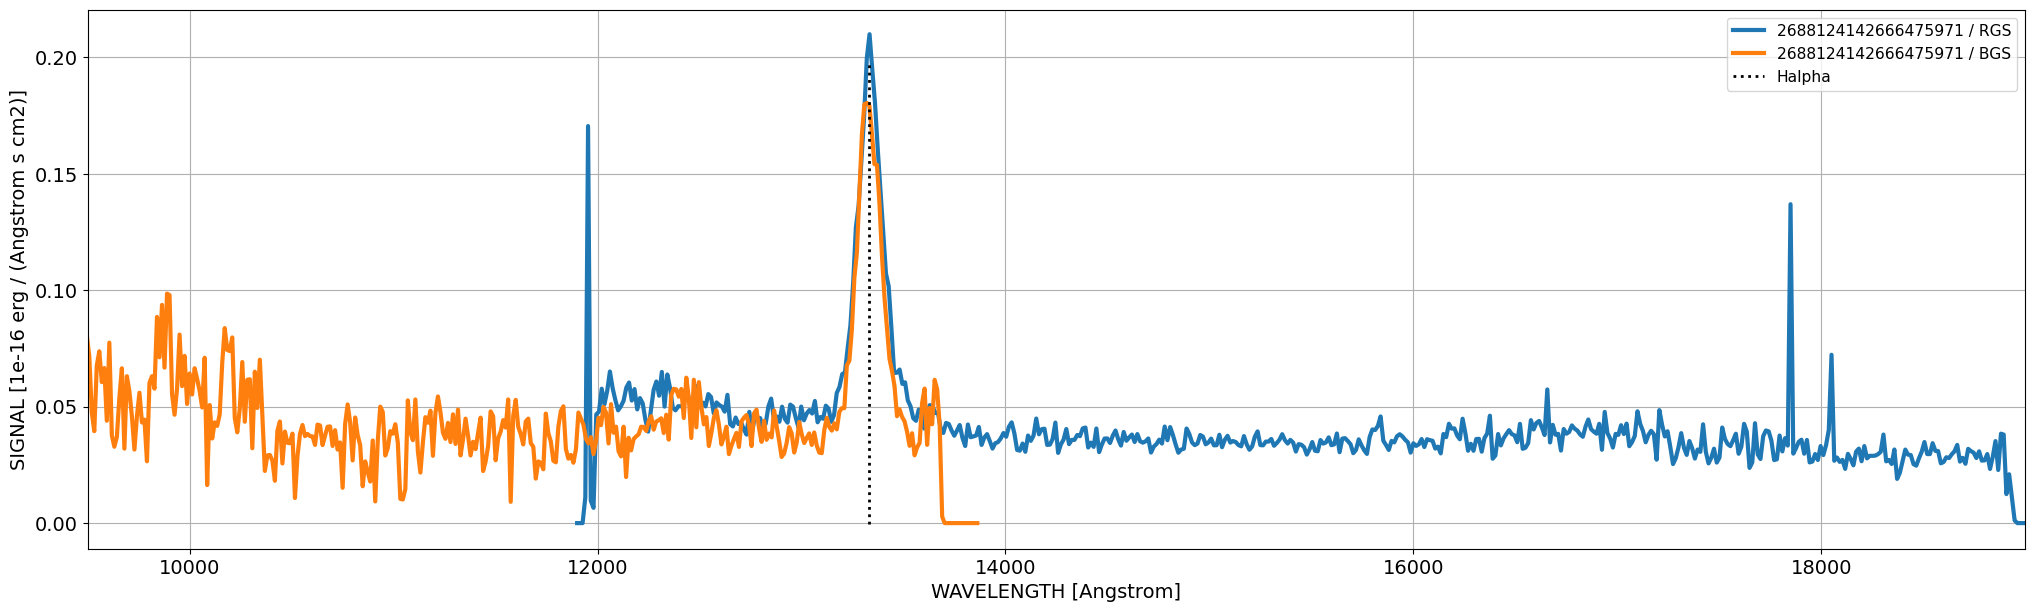

In [24]:
rr       = len(res)
specs    = [Table.read(res['datalabs_path'][ii] + '/' + res['file_name'][ii], res['hdu_index'][ii]) for ii in range(rr)]
objs     = [res['object_id'][ii]                                                                    for ii in range(rr)]
lambda_r = [res['lambda_range'][ii]                                                                 for ii in range(rr)]

plt.rcdefaults()

fig = plt.figure(figsize=[25,7])
for ii in range(rr):  
    plt.plot(specs[ii]['WAVELENGTH'],  specs[ii]['SIGNAL'], label = f'{objs[ii]} / {lambda_r[ii]}', linewidth = 3)
plt.grid()

# Add line ifo
jj = 1
plt.vlines(x=sp_line_res['spe_line_central_wl_gf'][jj], ymin=specs[1]['SIGNAL'].min(), ymax=specs[1]['SIGNAL'].max()*1.1, color = 'black', 
           linewidth = 2, label = sp_line_res['spe_line_name'][jj], linestyles=':')

plt.xlim([9500,19000])

utils.make_canvas(xlabel=f"WAVELENGTH [{specs[0]['WAVELENGTH'].unit}]", ylabel=f"SIGNAL [{specs[0]['SIGNAL'].unit}]", fontsize = 14, legend = True)
plt.show()

#### This example continues in the complementary "Cutouts_DR1" tutorial (see its first example).